<a href="https://colab.research.google.com/github/Ivan-cyber-max/rf-signal-jamming-detection/blob/main/RF_Jamming_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Success! Generated 4000 RF I/Q Signal captures.
Dataset shape: (4000, 2, 256) -> (Samples, 2 I/Q Channels, 256 Time Steps)


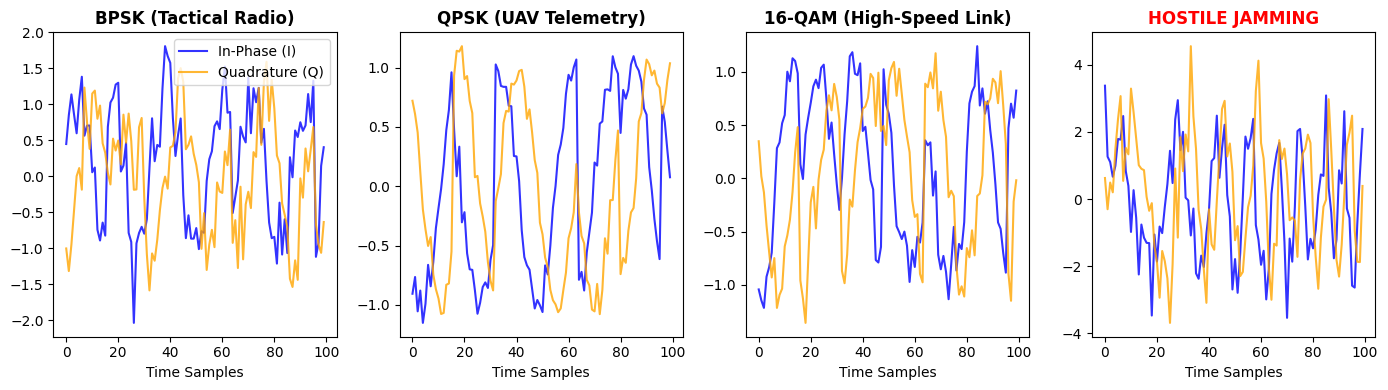

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def generate_rf_signal(signal_type, seq_len=256):
    """Generates realistic I/Q (In-phase & Quadrature) RF waveforms with channel noise and jamming."""
    t = np.linspace(0, 1, seq_len)
    carrier_freq = np.random.uniform(8, 12) # Random slight carrier frequency offset
    phase_offset = np.random.uniform(0, 2 * np.pi)

    # Base thermal noise (AWGN)
    snr_db = np.random.uniform(5, 18)
    noise_power = 10 ** (-snr_db / 10.0)
    noise_i = np.random.normal(0, np.sqrt(noise_power / 2), seq_len)
    noise_q = np.random.normal(0, np.sqrt(noise_power / 2), seq_len)

    if signal_type == 0:   # BPSK (Binary Phase Shift Keying - Rugged Tactical Comms)
        symbols = np.random.choice([-1, 1], size=16)
        baseband = np.repeat(symbols, seq_len // 16)
        i_wave = baseband * np.cos(2 * np.pi * carrier_freq * t + phase_offset)
        q_wave = baseband * np.sin(2 * np.pi * carrier_freq * t + phase_offset)

    elif signal_type == 1: # QPSK (Quadrature Phase Shift Keying - Drone Telemetry)
        sym_i = np.random.choice([-0.707, 0.707], size=16)
        sym_q = np.random.choice([-0.707, 0.707], size=16)
        bb_i = np.repeat(sym_i, seq_len // 16)
        bb_q = np.repeat(sym_q, seq_len // 16)
        i_wave = bb_i * np.cos(2 * np.pi * carrier_freq * t) - bb_q * np.sin(2 * np.pi * carrier_freq * t)
        q_wave = bb_i * np.sin(2 * np.pi * carrier_freq * t) + bb_q * np.cos(2 * np.pi * carrier_freq * t)

    elif signal_type == 2: # 16-QAM (High-Data-Rate Tactical Link)
        levels = [-0.948, -0.316, 0.316, 0.948]
        bb_i = np.repeat(np.random.choice(levels, size=16), seq_len // 16)
        bb_q = np.repeat(np.random.choice(levels, size=16), seq_len // 16)
        i_wave = bb_i * np.cos(2 * np.pi * carrier_freq * t) - bb_q * np.sin(2 * np.pi * carrier_freq * t)
        q_wave = bb_i * np.sin(2 * np.pi * carrier_freq * t) + bb_q * np.cos(2 * np.pi * carrier_freq * t)

    elif signal_type == 3: # HOSTILE JAMMING (Sweeping Chirp + High-Power Barrage Interference)
        chirp_freq = np.linspace(5, 45, seq_len) # Rapidly sweeping jamming tone
        jam_power = np.random.uniform(1.5, 2.5)
        i_wave = jam_power * np.cos(2 * np.pi * chirp_freq * t) + np.random.normal(0, 0.8, seq_len)
        q_wave = jam_power * np.sin(2 * np.pi * chirp_freq * t) + np.random.normal(0, 0.8, seq_len)

    # Combine signal with channel noise -> Shape: (2, 256) representing [I-channel, Q-channel]
    iq_sample = np.vstack([i_wave + noise_i, q_wave + noise_q]).astype(np.float32)
    return iq_sample

# Generate 4,000 RF captures (1,000 per class)
rf_classes = ['BPSK (Tactical Radio)', 'QPSK (UAV Telemetry)', '16-QAM (High-Speed Link)', 'HOSTILE JAMMING']
X_rf, y_rf = [], []

for cls_id in range(4):
    for _ in range(1000):
        X_rf.append(generate_rf_signal(cls_id))
        y_rf.append(cls_id)

X_rf = np.array(X_rf)
y_rf = np.array(y_rf)

print(f"Success! Generated {len(X_rf)} RF I/Q Signal captures.")
print(f"Dataset shape: {X_rf.shape} -> (Samples, 2 I/Q Channels, 256 Time Steps)")

# Plot 1 sample waveform from each of the 4 classes
plt.figure(figsize=(14, 4))
for i in range(4):
    idx = i * 1000
    plt.subplot(1, 4, i+1)
    plt.plot(X_rf[idx][0][:100], label='In-Phase (I)', color='blue', alpha=0.8)
    plt.plot(X_rf[idx][1][:100], label='Quadrature (Q)', color='orange', alpha=0.8)
    plt.title(rf_classes[i], fontweight='bold', color='red' if i==3 else 'black')
    plt.xlabel("Time Samples")
    if i == 0: plt.legend(loc='upper right')

plt.tight_layout()
plt.show()


Training Electronic Warfare AI on: cpu

Starting RF Spectrum Classifier Training...
Epoch [ 1/15] | Loss: 0.7400 | Test Accuracy: 72.75%
Epoch [ 3/15] | Loss: 0.3354 | Test Accuracy: 77.38%
Epoch [ 6/15] | Loss: 0.0467 | Test Accuracy: 91.88%
Epoch [ 9/15] | Loss: 0.0143 | Test Accuracy: 99.38%
Epoch [12/15] | Loss: 0.0152 | Test Accuracy: 98.38%
Epoch [15/15] | Loss: 0.0167 | Test Accuracy: 99.38%

Training Complete! Saved model as 'rf_jamming_classifier.pth'

=== ELECTRONIC WARFARE CLASSIFICATION REPORT ===
                          precision    recall  f1-score   support

   BPSK (Tactical Radio)       0.98      1.00      0.99       200
    QPSK (UAV Telemetry)       1.00      0.97      0.99       200
16-QAM (High-Speed Link)       1.00      1.00      1.00       200
         HOSTILE JAMMING       1.00      1.00      1.00       200

                accuracy                           0.99       800
               macro avg       0.99      0.99      0.99       800
            weighted 

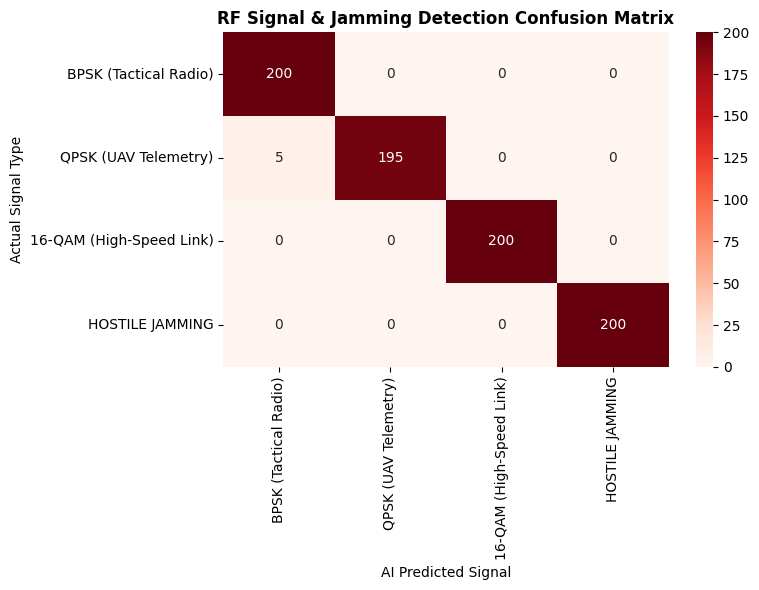

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# 1. Set hardware device (runs fast on CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training Electronic Warfare AI on: {device}")

# 2. Split 4,000 RF captures into 3,200 training and 800 unseen test signals
X_tensor = torch.tensor(X_rf, dtype=torch.float32)
y_tensor = torch.tensor(y_rf, dtype=torch.long)

X_train, X_test, y_train, y_test = train_test_split(
    X_tensor, y_tensor, test_size=0.2, random_state=42, stratify=y_tensor
)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=64, shuffle=False)

# 3. Define the 1D Convolutional Neural Network for I/Q Signal Processing
class RFJammingNet(nn.Module):
    def __init__(self, num_classes=4):
        super(RFJammingNet, self).__init__()
        # Input has 2 channels: In-phase (I) and Quadrature (Q)
        self.conv_layers = nn.Sequential(
            nn.Conv1d(2, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(8)
        )
        self.classifier = nn.Sequential(
            nn.Linear(128 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

rf_model = RFJammingNet(num_classes=4).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(rf_model.parameters(), lr=0.001)

# 4. Train for 15 Epochs
print("\nStarting RF Spectrum Classifier Training...")
for epoch in range(15):
    rf_model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = rf_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Evaluate on unseen test signals
    rf_model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = rf_model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    if (epoch + 1) % 3 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:2d}/15] | Loss: {running_loss/len(train_loader):.4f} | Test Accuracy: {100*correct/total:.2f}%")

# 5. Save the trained Electronic Warfare model weights
torch.save(rf_model.state_dict(), "rf_jamming_classifier.pth")
print("\nTraining Complete! Saved model as 'rf_jamming_classifier.pth'")

# 6. Generate Confusion Matrix for your Thesis Report
rf_model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = rf_model(inputs.to(device))
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print("\n=== ELECTRONIC WARFARE CLASSIFICATION REPORT ===")
print(classification_report(all_labels, all_preds, target_names=rf_classes))

plt.figure(figsize=(8, 6))
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=rf_classes, yticklabels=rf_classes)
plt.title("RF Signal & Jamming Detection Confusion Matrix", fontweight='bold')
plt.xlabel("AI Predicted Signal")
plt.ylabel("Actual Signal Type")
plt.tight_layout()
plt.show()


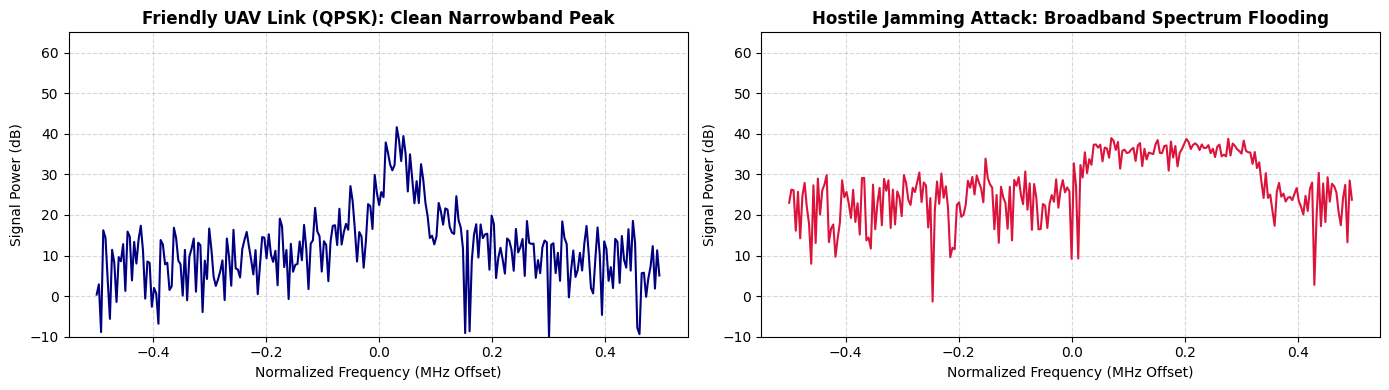

In [3]:
# Compute Fast Fourier Transform (FFT) Power Spectral Density to visualize frequency jamming
def plot_rf_spectrum(iq_sample, title, color):
    # Combine I and Q into a complex radio signal: I + jQ
    complex_sig = iq_sample[0] + 1j * iq_sample[1]
    fft_vals = np.fft.fftshift(np.fft.fft(complex_sig))
    power_db = 20 * np.log10(np.abs(fft_vals) + 1e-6)
    freqs = np.fft.fftshift(np.fft.fftfreq(len(complex_sig)))

    plt.plot(freqs, power_db, color=color, linewidth=1.5)
    plt.title(title, fontweight='bold')
    plt.xlabel("Normalized Frequency (MHz Offset)")
    plt.ylabel("Signal Power (dB)")
    plt.ylim(-10, 65)
    plt.grid(True, linestyle='--', alpha=0.5)

plt.figure(figsize=(14, 4))

# 1. Friendly UAV Telemetry (QPSK) - Concentrated narrow power peak
plt.subplot(1, 2, 1)
plot_rf_spectrum(X_rf[1000], "Friendly UAV Link (QPSK): Clean Narrowband Peak", "navy")

# 2. Hostile Jamming Attack - Elevated broadband noise floor & sweeping spikes
plt.subplot(1, 2, 2)
plot_rf_spectrum(X_rf[3000], "Hostile Jamming Attack: Broadband Spectrum Flooding", "crimson")

plt.tight_layout()
plt.show()
